In [1]:
# ruff: noqa: T201, T203, ERA001, BLE001, E402
from __future__ import annotations

import json
import logging
import os
from collections import defaultdict
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import tiktoken
from dotenv import load_dotenv

while Path.cwd().name in ["notebooks", "evaluation"]:
    os.chdir("..")

from config.config import DATA_DIR, METRICS_DIR
from config.runs_vars import DATASET_SUBSETS_MAP
from src.estimations import (
    SUBTASK_NUM_PAIRS,
    ModelMetadata,
    UsageProfile,
    build_cost_comparison_table,
    build_cost_table_from_real_usage,
    collect_all_experiment_stats,
    collect_all_usage_stats,
    estimate_dataset_cost,
    estimate_full_eval_cost,
    estimate_task_cost,
    fetch_model_metadata,
    format_cost,
    get_all_tasks,
    get_num_pairs,
    summarize_model_pricing,
)
from src.prompts.prompts import (
    prompt_direct_entity,
    prompt_direct_entity_with_synonyms,
)
from src.prompts.system import INTUITIVE_NATURAL_LANGUAGE_JUDGEMENT_MESSAGE

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
logging.getLogger().setLevel(logging.WARNING)
load_dotenv()

%load_ext autoreload
%autoreload 2

In [2]:
prompt_functions = [
    function.__name__
    for function in [
        prompt_direct_entity,
        # prompt_direct_entity_ontological,
        prompt_direct_entity_with_synonyms,
        # prompt_sequential_hierarchy,
        # prompt_sequential_hierarchy_ontological,
        # prompt_sequential_hierarchy_with_synonyms,
    ]
]

SELECTED_N_SAMPLES = [0, 1, 2, 3, 5, 8, 11, 15, 20, 26, 33, 41, 45]

tokenizer = tiktoken.get_encoding("cl100k_base")

# Structure: tokens_usage[subset][prompt_function][version] = list of token counts per pair
tokens_usage = defaultdict(lambda: defaultdict(lambda: defaultdict(list)))

for version in range(10):
    for dataset, subsets in DATASET_SUBSETS_MAP.items():
        for subset in subsets:
            prompts_path = DATA_DIR / "preparation" / f"{dataset}/{subset}/v{version}.json"
            if not prompts_path.exists():
                print(f"Missing file: {prompts_path}")
                continue

            with prompts_path.open() as f:
                data = json.load(f)

            # Estimate token usage per *pair* of samples
            for prompt_function, messages in data["OpenAI"].items():
                if prompt_function not in prompt_functions:
                    continue

                n_pairs = len(messages) // 2
                for i in range(n_pairs):
                    msg_pos = messages[2 * i]
                    msg_neg = messages[2 * i + 1]
                    input_tokens = tokenizer.encode(msg_pos["input"]) + tokenizer.encode(msg_neg["input"])
                    output_tokens = tokenizer.encode(msg_pos["output"]) + tokenizer.encode(msg_neg["output"])
                    total_tokens = len(input_tokens) + len(output_tokens)
                    tokens_usage[subset][prompt_function][version].append(total_tokens)

# --- Compute baseline per subset/prompt ---
system_prompt_tokens = len(tiktoken.get_encoding("cl100k_base").encode(INTUITIVE_NATURAL_LANGUAGE_JUDGEMENT_MESSAGE))

baselines = defaultdict(lambda: defaultdict(float))
for subset, subset_usage in tokens_usage.items():
    for func_name, func_usage in subset_usage.items():
        all_tokens = [t for tokens in func_usage.values() for t in tokens]
        baselines[subset][func_name] = int(np.mean(all_tokens)) if all_tokens else 0


n_rows = len(tokens_usage)
n_cols = len(prompt_functions)

plot = False
if plot:
    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(4 * n_cols, 3 * n_rows),
        sharey="row",
        squeeze=False,
    )

    # Sort keys for consistent column order
    subset_list = list(tokens_usage.keys())
    for i, func_name in enumerate(prompt_functions):
        for j, subset in enumerate(subset_list):
            ax = axes[j, i]
            subset_usage = tokens_usage[subset]
            func_usage = subset_usage.get(func_name, {})

            if not func_usage:
                ax.set_visible(False)
                continue

            baseline = baselines[subset][func_name] + system_prompt_tokens

            for version, tokens in func_usage.items():
                if len(tokens) == 0:
                    continue

                cumulative_tokens = pd.Series(tokens).cumsum()
                cumulative_tokens = pd.concat([pd.Series([baseline]), baseline + cumulative_tokens])

                # select only specified sample counts
                valid_idx = [n for n in SELECTED_N_SAMPLES if n < len(cumulative_tokens)]
                sampled_tokens = cumulative_tokens.iloc[valid_idx]

                ax.plot(valid_idx, sampled_tokens, marker="o", label=f"v{version}")

            if i == 0:
                ax.set_ylabel("Cumulative Tokens (with baseline)")
            if j == n_cols - 1:
                ax.set_xlabel("Number of Pair Samples")

            ax.set_title(f"{subset}\n{func_name}", fontsize=9)
            ax.legend(fontsize=8)

    plt.tight_layout()

In [3]:
TOKENS_LIMIT = 4_000_000
TOKENS_LIMIT = None

summary_data = []
for subset, subset_usage in tokens_usage.items():
    for func_name, func_usage in subset_usage.items():
        baseline = baselines[subset][func_name] + system_prompt_tokens

        version_cumuls = {}
        for version, tokens in func_usage.items():
            if len(tokens) == 0:
                continue
            cumulative_tokens = pd.Series(tokens).cumsum()
            version_cumuls[version] = pd.concat([pd.Series([baseline]), baseline + cumulative_tokens])
            if TOKENS_LIMIT is not None:
                version_cumuls[version] = (TOKENS_LIMIT / version_cumuls[version]).astype(int)

        row = {}
        for n in SELECTED_N_SAMPLES:
            vals = []
            for cumulative_tokens in version_cumuls.values():
                if n < len(cumulative_tokens):
                    vals.append(cumulative_tokens.iloc[n])
            row[n] = max(vals) if vals else None

        summary_data.append((subset, func_name, row))

rows = []
for subset, func_name, row_dict in summary_data:
    row = {"Dataset": subset, "Prompt": func_name}
    row.update(row_dict)
    rows.append(row)

df_summary = pd.DataFrame(rows)
df_summary = df_summary.set_index(["Dataset", "Prompt"])
df_summary = df_summary[SELECTED_N_SAMPLES]

df_summary

0    1     2     3  \
Dataset             Prompt                                                     
ncit-doid           prompt_direct_entity                212  381   557   750   
                    prompt_direct_entity_with_synonyms  249  571   763   950   
omim-ordo           prompt_direct_entity                213  414   594   736   
                    prompt_direct_entity_with_synonyms  269  535   762   951   
snomed-fma.body     prompt_direct_entity                247  495   698   884   
                    prompt_direct_entity_with_synonyms  265  535   747   956   
snomed-ncit.neoplas prompt_direct_entity                234  460   633   826   
                    prompt_direct_entity_with_synonyms  249  503   680   916   
snomed-ncit.pharm   prompt_direct_entity                226  415   602   769   
                    prompt_direct_entity_with_synonyms  231  454   609   797   
fma-nci             prompt_direct_entity                249  461   707   953   
                    prompt_direct_entity_with_synonyms  245  453   695   937   
fma-snomed          prompt_direct_entity                250  516   715   923   
                    prompt_direct_entity_with_synonyms  246  509   709   909   
snomed-nci          prompt_direct_entity                261  765  1119  1305   
                    prompt_direct_entity_with_synonyms  257  757  1128  1310   
human-mouse         prompt_direct_entity                202  369   519   678   
                    prompt_direct_entity_with_synonyms  268  509   744  1039   

                                                           5     8    11  \
Dataset             Prompt                                                 
ncit-doid           prompt_direct_entity                1058  1546  2060   
                    prompt_direct_entity_with_synonyms  1471  2033  2635   
omim-ordo           prompt_direct_entity                1073  1577  2078   
                    prompt_direct_entity_with_synonyms  1382  2058  2707   
snomed-fma.body     prompt_direct_entity                1301  1891  2456   
                    prompt_direct_entity_with_synonyms  1424  2079  2671   
snomed-ncit.neoplas prompt_direct_entity                1195  1740  2302   
                    prompt_direct_entity_with_synonyms  1311  1959  2511   
snomed-ncit.pharm   prompt_direct_entity                1159  1690  2223   
                    prompt_direct_entity_with_synonyms  1180  1737  2324   
fma-nci             prompt_direct_entity                1332  2069  2699   
                    prompt_direct_entity_with_synonyms  1308  2033  2651   
fma-snomed          prompt_direct_entity                1368  1973  2566   
                    prompt_direct_entity_with_synonyms  1351  1931  2509   
snomed-nci          prompt_direct_entity                2304  2830  3364   
                    prompt_direct_entity_with_synonyms  2303  2817  3332   
human-mouse         prompt_direct_entity                 996  1439  1890   
                    prompt_direct_entity_with_synonyms  1533  2223  3015   

                                                          15    20    26  \
Dataset             Prompt                                                 
ncit-doid           prompt_direct_entity                2724  3527  4532   
                    prompt_direct_entity_with_synonyms  3487  4549  5775   
omim-ordo           prompt_direct_entity                2768  3580  4564   
                    prompt_direct_entity_with_synonyms  3600  4620  5859   
snomed-fma.body     prompt_direct_entity                3225  4292  5470   
                    prompt_direct_entity_with_synonyms  3484  4621  5890   
snomed-ncit.neoplas prompt_direct_entity                3103  4021  5140   
                    prompt_direct_entity_with_synonyms  3295  4365  5547   
snomed-ncit.pharm   prompt_direct_entity                2943  3857  4887   
                    prompt_direct_entity_with_synonyms  3126  4023  5090   
fma-nci             prom

In [4]:
print("Candidate pair counts per task:")
for subset, sizes in SUBTASK_NUM_PAIRS.items():
    print(f"  {subset}: reduced={sizes['reduced']}, full={sizes['full']}")

print(f"\nAll tasks: {get_all_tasks()}")

Candidate pair counts per task:
  ncit-doid: reduced=3281, full=4687
  omim-ordo: reduced=2606, full=3722
  snomed-fma.body: reduced=5080, full=7257
  snomed-ncit.neoplas: reduced=2664, full=3805
  snomed-ncit.pharm: reduced=4063, full=5804
  fma-nci: reduced=1770, full=3024
  fma-snomed: reduced=2904, full=9008
  snomed-nci: reduced=5144, full=18844
  human-mouse: reduced=508, full=1516

All tasks: ['ncit-doid', 'omim-ordo', 'snomed-fma.body', 'snomed-ncit.neoplas', 'snomed-ncit.pharm', 'fma-nci', 'fma-snomed', 'snomed-nci', 'human-mouse']


In [5]:
all_model_metadata = fetch_model_metadata()
print(f"Fetched pricing for {len(all_model_metadata)} models\n")

pricing_summary = summarize_model_pricing(all_model_metadata)
display(pricing_summary.sort_values("Input ($/1M)"))

Model 'nvidia|nemotron-3-nano-omni-30b-a3b-reasoning' (→ nvidia/nemotron-3-nano-omni-30b-a3b-reasoning) not found on OpenRouter.
Model 'anthropic.claude-3-sonnet-20240229-v1:0' (→ anthropic/claude-3-sonnet) not found on OpenRouter.
Model 'gemini-1.5-flash' (→ google/gemini-1.5-flash) not found on OpenRouter.
No OpenRouter mapping for 'mistralai' (local model?), skipping.
Model 'mistralai|mistral-large-2512meta-llama|llama-4-scout' (→ mistralai/mistral-large-2512meta-llama/llama-4-scout) not found on OpenRouter.
No OpenRouter mapping for 'qwen3-8B' (local model?), skipping.
Model 'gemini-1.5-flash-lite' (→ google/gemini-1.5-flash) not found on OpenRouter.
No OpenRouter mapping for 'google' (local model?), skipping.
Model 'anthropic.claude-instant-v1' (→ anthropic/claude-instant-1.2) not found on OpenRouter.
No OpenRouter mapping for 'qwen3-1.7B' (local model?), skipping.


Fetched pricing for 76 models



,Input ($/1M),Output ($/1M),Cache ($/1M),Reasoning ($/1M)
Model,,,,
mistralai|mistral-nemo,0.020,0.030,NaN,None
openai|gpt-oss-20b,0.030,0.140,NaN,None
amazon|nova-micro-v1,0.035,0.140,NaN,None
openai|gpt-oss-120b,0.039,0.180,NaN,None
google|gemma-3-4b-it,0.040,0.080,NaN,None
qwen|qwen3.5-9b,0.040,0.150,NaN,None
google|gemma-3-12b-it,0.040,0.130,NaN,None
qwen|qwen3-8b,0.050,0.400,0.050000,None
gpt-5-nano,0.050,0.400,0.010000,None


In [6]:
all_baselines = []
for subset, subset_usage in baselines.items():
    for func_name, mean_tokens in subset_usage.items():
        all_baselines.append(mean_tokens)
avg_tokens_per_pair = np.mean(all_baselines) if all_baselines else 300
print(f"Average tokens per pair (tiktoken estimate): {avg_tokens_per_pair:.0f}")

base_usage = UsageProfile(
    mean_input_tokens=avg_tokens_per_pair * 0.95,
    mean_output_tokens=avg_tokens_per_pair * 0.05,
)
print(f"Base usage profile: input={base_usage.mean_input_tokens:.0f}, output={base_usage.mean_output_tokens:.0f}")

COMPARE_MODELS = [
    "gemini-2.0-flash-lite", "gemini-2.0-flash", "gemini-2.5-flash", "gemini-2.5-flash-lite",
    "gemini-2.5-pro", "gpt-4.1-nano", "gpt-5-nano",
    "openai|gpt-4o-mini", "openai|gpt-5-nano",
    "meta-llama|llama-4-scout", "google|gemma-3-4b-it", "google|gemma-3-12b-it",
    "mistralai|ministral-3b-2512", "qwen|qwen3-32b",
    "deepseek|deepseek-v3.2",
    # --- New models (Apr-May 2026) ---
    "x-ai|grok-4.3",
    "mistralai|mistral-medium-3-5",
    "ibm-granite|granite-4.1-8b",
    "nvidia|nemotron-3-nano-omni-30b-a3b-reasoning",
]
selected_models = {k: v for k, v in all_model_metadata.items() if k in COMPARE_MODELS}
print(f"\nSelected {len(selected_models)} models for comparison")

cost_table = build_cost_comparison_table(
    models=selected_models,
    usage=base_usage,
    size="reduced",
    n_versions=1,
    n_prompts=2,
)
_str_cols = cost_table.select_dtypes(include="object").columns
print("\n=== Base cost comparison (reduced set, 2 prompts, 1 version) ===")
display(cost_table.style.format({c: "${:.4f}" for c in cost_table.columns if c not in _str_cols}))

Average tokens per pair (tiktoken estimate): 193
Base usage profile: input=183, output=10

Selected 18 models for comparison

=== Base cost comparison (reduced set, 2 prompts, 1 version) ===


,Model,Config,Experiment,ncit-doid,omim-ordo,snomed-fma.body,snomed-ncit.neoplas,snomed-ncit.pharm,fma-nci,fma-snomed,snomed-nci,human-mouse,Total
0,google|gemma-3-12b-it,base,google|gemma-3-12b-it&base,$0.0563,$0.0448,$0.0872,$0.0457,$0.0698,$0.0304,$0.0499,$0.0883,$0.0087,$0.4812
1,gpt-4.1-nano,base,gpt-4.1-nano&base,$0.1456,$0.1156,$0.2254,$0.1182,$0.1803,$0.0785,$0.1289,$0.2283,$0.0225,$1.2434
2,meta-llama|llama-4-scout,base,meta-llama|llama-4-scout&base,$0.1152,$0.0915,$0.1784,$0.0935,$0.1427,$0.0622,$0.1020,$0.1806,$0.0178,$0.9839
3,openai|gpt-5-nano,base,openai|gpt-5-nano&base,$0.0855,$0.0679,$0.1323,$0.0694,$0.1058,$0.0461,$0.0756,$0.1340,$0.0132,$0.7299
4,gemini-2.5-flash,base,gemini-2.5-flash&base,$0.5191,$0.4123,$0.8037,$0.4215,$0.6428,$0.2800,$0.4595,$0.8139,$0.0804,$4.4332
5,openai|gpt-4o-mini,base,openai|gpt-4o-mini&base,$0.2184,$0.1735,$0.3382,$0.1773,$0.2705,$0.1178,$0.1933,$0.3424,$0.0338,$1.8652
6,gemini-2.0-flash,base,gemini-2.0-flash&base,$0.1456,$0.1156,$0.2254,$0.1182,$0.1803,$0.0785,$0.1289,$0.2283,$0.0225,$1.2434
7,gpt-5-nano,base,gpt-5-nano&base,$0.0855,$0.0679,$0.1323,$0.0694,$0.1058,$0.0461,$0.0756,$0.1340,$0.0132,$0.7299
8,x-ai|grok-4.3,base,x-ai|grok-4.3&base,$1.6618,$1.3199,$2.5729,$1.3493,$2.0578,$0.8965,$1.4708,$2.6053,$0.2573,$14.1915
9,gemini-2.5-pro,base,gemini-2.5-pro&base,$2.1365,$1.6970,$3.3080,$1.7348,$2.6458,$1.1526,$1.8910,$3.3497,$0.3308,$18.2463


Cost matrix shape: (864, 13)


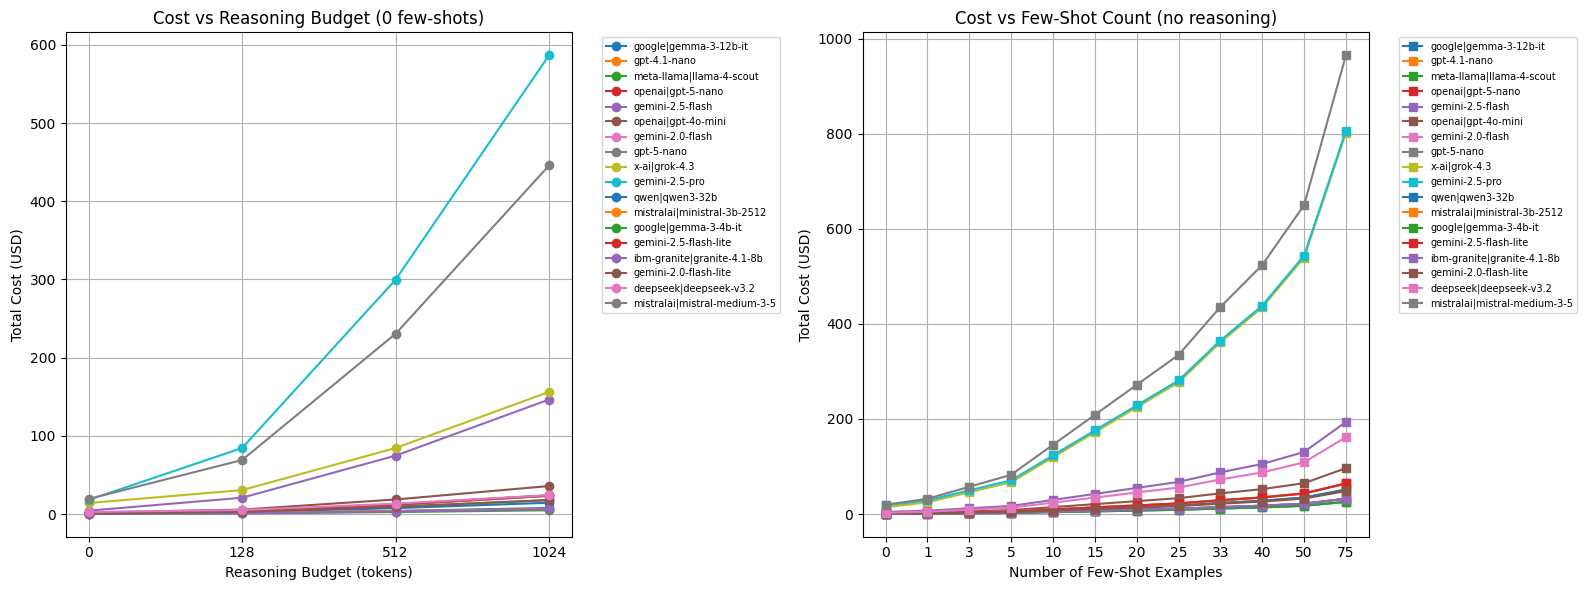

In [7]:
REASONING_BUDGETS = [0, 128, 512, 1024]
FEW_SHOT_CONFIGS = [0, 1, 3, 5, 10, 15, 20, 25, 33, 40, 50, 75]
TOKENS_PER_SHOT = 150

cost_matrix = build_cost_comparison_table(
    models=selected_models,
    usage=base_usage,
    size="reduced",
    n_versions=1,
    n_prompts=2,
    reasoning_budgets=REASONING_BUDGETS,
    few_shot_configs=FEW_SHOT_CONFIGS,
    tokens_per_shot=TOKENS_PER_SHOT,
)

print(f"Cost matrix shape: {cost_matrix.shape}")
# display(cost_matrix.style.format({c: "${:.4f}" for c in cost_matrix.columns if c not in ["Model", "Config"]}))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

no_shots = cost_matrix[cost_matrix["Config"].str.contains("shots=0")]
for model_name in selected_models:
    model_data = no_shots[no_shots["Model"] == model_name]
    if not model_data.empty:
        labels = [c.split(",")[0].replace("reason=", "") for c in model_data["Config"]]
        axes[0].plot(labels, model_data["Total"], marker="o", label=model_name)

axes[0].set_xlabel("Reasoning Budget (tokens)")
axes[0].set_ylabel("Total Cost (USD)")
axes[0].set_title("Cost vs Reasoning Budget (0 few-shots)")
axes[0].legend(bbox_to_anchor=(1.05, 1), fontsize=7)
axes[0].grid(True)

no_reasoning = cost_matrix[cost_matrix["Config"].str.contains("reason=0")]
for model_name in selected_models:
    model_data = no_reasoning[no_reasoning["Model"] == model_name]
    if not model_data.empty:
        labels = [c.split(",")[1].replace("shots=", "").strip() for c in model_data["Config"]]
        axes[1].plot(labels, model_data["Total"], marker="s", label=model_name)

axes[1].set_xlabel("Number of Few-Shot Examples")
axes[1].set_ylabel("Total Cost (USD)")
axes[1].set_title("Cost vs Few-Shot Count (no reasoning)")
axes[1].legend(bbox_to_anchor=(1.05, 1), fontsize=7)
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [8]:
ANALYSIS_MODEL_NAME = "gemini-2.5-flash"
analysis_model = all_model_metadata.get(ANALYSIS_MODEL_NAME)
if analysis_model is None:
    print(f"Model '{ANALYSIS_MODEL_NAME}' not found, using first available")
    ANALYSIS_MODEL_NAME = next(iter(selected_models))
    analysis_model = selected_models[ANALYSIS_MODEL_NAME]

print(f"=== Per-dataset cost breakdown: {ANALYSIS_MODEL_NAME} ===\n")
for dataset_name, subsets in DATASET_SUBSETS_MAP.items():
    costs = estimate_dataset_cost(analysis_model, dataset_name, base_usage, size="reduced", n_versions=1)
    print(f"  {dataset_name}:")
    for subset, cost in costs.items():
        n_pairs = get_num_pairs(subset, "reduced")
        print(f"    {subset:30s} ({n_pairs:5d} pairs) -> {format_cost(cost * 2)} (2 prompts)")
    total = sum(costs.values()) * 2
    print(f"    {'TOTAL':30s} -> {format_cost(total)}")
    print()

full_costs = estimate_full_eval_cost(analysis_model, base_usage, size="reduced", n_versions=1, n_prompts=2)
print(f"Full evaluation total: {format_cost(sum(full_costs.values()))}")

full_costs_10v = estimate_full_eval_cost(analysis_model, base_usage, size="reduced", n_versions=10, n_prompts=2)
print(f"Full evaluation total (10 versions): {format_cost(sum(full_costs_10v.values()))}")

=== Per-dataset cost breakdown: gemini-2.5-flash ===

  bioml-2024:
    ncit-doid                      ( 3281 pairs) -> $0.519 (2 prompts)
    omim-ordo                      ( 2606 pairs) -> $0.412 (2 prompts)
    snomed-fma.body                ( 5080 pairs) -> $0.804 (2 prompts)
    snomed-ncit.neoplas            ( 2664 pairs) -> $0.421 (2 prompts)
    snomed-ncit.pharm              ( 4063 pairs) -> $0.643 (2 prompts)
    TOTAL                          -> $2.80

  largebio:
    fma-nci                        ( 1770 pairs) -> $0.280 (2 prompts)
    fma-snomed                     ( 2904 pairs) -> $0.459 (2 prompts)
    snomed-nci                     ( 5144 pairs) -> $0.814 (2 prompts)
    TOTAL                          -> $1.55

  anatomy:
    human-mouse                    (  508 pairs) -> $0.080 (2 prompts)
    TOTAL                          -> $0.080

Full evaluation total: $4.43
Full evaluation total (10 versions): $44.33


In [9]:
usage_stats_df = collect_all_usage_stats()
print(f"Collected usage stats from {len(usage_stats_df)} experiment-prompt combinations")

# Drop rows with NaN in key usage columns
key_cols = ["mean_input_tokens", "mean_output_tokens"]
usage_stats_df = usage_stats_df.dropna(subset=key_cols)
print(f"After dropping NaN: {len(usage_stats_df)} rows")

if not usage_stats_df.empty:
    display(usage_stats_df.head(10))

# Build per-(model, exp_name, subset) UsageProfiles from real data
# and a fallback per (model, exp_name) for subsets without real data
all_tasks = get_all_tasks()

experiment_usage: dict[tuple[str, str, str], UsageProfile] = {}  # (model, exp_name, subset) -> UsageProfile
experiment_fallback: dict[tuple[str, str], UsageProfile] = {}    # (model, exp_name) -> avg UsageProfile

if not usage_stats_df.empty:
    for (model, exp_name), group in usage_stats_df.groupby(["model", "exp_name"]):
        subset_profiles: dict[str, UsageProfile] = {}
        for subset, sub_group in group.groupby("subset"):
            avg_stats = {
                "mean_input_tokens": sub_group["mean_input_tokens"].mean(),
                "mean_output_tokens": sub_group["mean_output_tokens"].mean(),
                "mean_input_cached_tokens": sub_group.get("mean_input_cached_tokens", pd.Series([0])).mean(),
                "mean_output_reasoning_tokens": sub_group.get("mean_output_reasoning_tokens", pd.Series([0])).mean(),
                "mean_proc_time": sub_group.get("mean_proc_time", pd.Series([0])).mean(),
            }
            profile = UsageProfile.from_usage_stats(avg_stats)
            experiment_usage[(model, exp_name, subset)] = profile
            subset_profiles[subset] = profile

        # Build fallback as average across all available subsets for this experiment
        if subset_profiles:
            experiment_fallback[(model, exp_name)] = UsageProfile(
                mean_input_tokens=float(np.mean([p.mean_input_tokens for p in subset_profiles.values()])),
                mean_output_tokens=float(np.mean([p.mean_output_tokens for p in subset_profiles.values()])),
                mean_cached_tokens=float(np.mean([p.mean_cached_tokens for p in subset_profiles.values()])),
                mean_reasoning_tokens=float(np.mean([p.mean_reasoning_tokens for p in subset_profiles.values()])),
                mean_proc_time=float(np.mean([p.mean_proc_time for p in subset_profiles.values()])),
            )

    print(f"\nBuilt {len(experiment_usage)} real (model, exp_name, subset) profiles")
    print(f"Built {len(experiment_fallback)} fallback (model, exp_name) profiles")

    # Compute costs per (model, exp_name) across all tasks
    cost_rows = []
    for (model, exp_name), fallback in experiment_fallback.items():
        # Resolve pricing via model metadata
        model_meta = all_model_metadata.get(model)
        if model_meta is None:
            continue

        row: dict[str, Any] = {"Model": model, "Experiment": exp_name}
        total = 0.0
        real_count = 0
        scaled_count = 0
        for subset in all_tasks:
            profile = experiment_usage.get((model, exp_name, subset), fallback)
            is_real = (model, exp_name, subset) in experiment_usage
            cost = estimate_task_cost(model_meta, subset, profile, size="reduced", n_versions=1) * 2  # 2 prompts
            row[subset] = cost
            row[f"{subset}_source"] = "real" if is_real else "scaled"
            total += cost
            if is_real:
                real_count += 1
            else:
                scaled_count += 1
        row["Total"] = total
        row["real_tasks"] = real_count
        row["scaled_tasks"] = scaled_count
        cost_rows.append(row)

    real_usage_cost_df = pd.DataFrame(cost_rows)

    # Display cost table (without source columns for readability)
    display_cols = ["Model", "Experiment"] + all_tasks + ["Total", "real_tasks", "scaled_tasks"]
    cost_cols = [c for c in display_cols if c not in ["Model", "Experiment", "real_tasks", "scaled_tasks"]]
    print("\n=== Cost per experiment (real usage where available, scaled otherwise) ===")
    display(
        real_usage_cost_df[display_cols]
        .style.format({c: "${:.4f}" for c in cost_cols})
    )
else:
    print("\nNo real usage data found. Run inference pipelines to collect token usage statistics.")

Collected usage stats from 320 experiment-prompt combinations
After dropping NaN: 320 rows


,subset,dataset,model,experiment_type,exp_name,prompt,mean_input_tokens,mean_output_tokens,total_input_tokens,total_output_tokens,mean_input_cached_tokens,total_input_cached_tokens,mean_output_reasoning_tokens,total_output_reasoning_tokens,mean_proc_time,total_proc_time
0,fma-nci,largebio,bytedance-seed|seed-2.0-mini,open-weight-models,bytedance-seed|seed-2.0-mini,direct_entity_with_synonyms,316.511864,627.385311,280113.0,555236.0,NaN,NaN,NaN,NaN,NaN,NaN
1,fma-snomed,largebio,bytedance-seed|seed-2.0-mini,open-weight-models,bytedance-seed|seed-2.0-mini,direct_entity,316.581267,869.847796,459676.0,1263019.0,NaN,NaN,NaN,NaN,NaN,NaN
2,human-mouse,anatomy,nvidia|nemotron-3-nano-omni-30b-a3b-reasoning,models-estimation,nvidia|nemotron-3-nano-omni-30b-a3b-reasoning,direct_entity,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000
3,human-mouse,anatomy,nvidia|nemotron-3-nano-omni-30b-a3b-reasoning,models-estimation,nvidia|nemotron-3-nano-omni-30b-a3b-reasoning,direct_entity_with_synonyms,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000
4,human-mouse,anatomy,deepseek|deepseek-chat-v3-0324,models-estimation,deepseek|deepseek-chat-v3-0324,direct_entity,102.377953,6.011811,26004.0,1527.0,32.755906,8320.0,0.0,0.0,8.305057,2109.484594
5,human-mouse,anatomy,deepseek|deepseek-chat-v3-0324,models-estimation,deepseek|deepseek-chat-v3-0324,direct_entity_with_synonyms,127.602362,6.003937,32411.0,1525.0,41.322835,10496.0,0.0,0.0,44.976511,11424.033747
6,human-mouse,anatomy,qwen|qwen3-next-80b-a3b-instruct,models-estimation,qwen|qwen3-next-80b-a3b-instruct,direct_entity,111.858268,18.842520,28412.0,4786.0,0.000000,0.0,0.0,0.0,7.731492,1963.798920
7,human-mouse,anatomy,qwen|qwen3-next-80b-a3b-instruct,models-estimation,qwen|qwen3-next-80b-a3b-instruct,direct_entity_with_synonyms,139.114173,25.562992,35335.0,6493.0,0.000000,0.0,0.0,0.0,4.794492,1217.801084
8,human-mouse,anatomy,moonshotai|kimi-k2.6,models-estimation,moonshotai|kimi-k2.6,direct_entity,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000
9,human-mouse,anatomy,moonshotai|kimi-k2.6,models-estimation,moonshotai|kimi-k2.6,direct_entity_with_synonyms,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000



Built 124 real (model, exp_name, subset) profiles
Built 122 fallback (model, exp_name) profiles

=== Cost per experiment (real usage where available, scaled otherwise) ===


,Model,Experiment,ncit-doid,omim-ordo,snomed-fma.body,snomed-ncit.neoplas,snomed-ncit.pharm,fma-nci,fma-snomed,snomed-nci,human-mouse,Total,real_tasks,scaled_tasks
0,amazon|nova-micro-v1,amazon|nova-micro-v1,$0.1514,$0.1202,$0.2344,$0.1229,$0.1875,$0.0817,$0.1340,$0.2373,$0.0234,$1.2928,1,8
1,anthropic|claude-haiku-4.5,anthropic|claude-haiku-4.5,$2.1810,$1.7323,$3.3769,$1.7709,$2.7009,$1.1766,$1.9304,$3.4195,$0.3377,$18.6262,1,8
2,anthropic|claude-opus-4.6,anthropic|claude-opus-4.6,$10.9761,$8.7180,$16.9944,$8.9120,$13.5922,$5.9213,$9.7149,$17.2085,$1.6994,$93.7368,1,8
3,anthropic|claude-opus-4.7,anthropic|claude-opus-4.7,$14.6932,$11.6704,$22.7496,$11.9301,$18.1952,$7.9265,$13.0049,$23.0362,$2.2750,$125.4811,1,8
4,anthropic|claude-sonnet-4.6,anthropic|claude-sonnet-4.6,$6.5632,$5.2129,$10.1618,$5.3290,$8.1275,$3.5406,$5.8091,$10.2899,$1.0162,$56.0501,1,8
5,anthropic|claude-sonnet-4.6,anthropic|claude-sonnet-4.6&reasoning_effort=high,$14.4369,$11.4668,$22.3528,$11.7220,$17.8778,$7.7883,$12.7781,$22.6344,$2.2353,$123.2924,1,8
6,anthropic|claude-sonnet-4.6,anthropic|claude-sonnet-4.6&reasoning_effort=low,$14.3287,$11.3809,$22.1852,$11.6341,$17.7438,$7.7299,$12.6823,$22.4647,$2.2185,$122.3682,1,8
7,anthropic|claude-sonnet-4.6,anthropic|claude-sonnet-4.6&reasoning_effort=medium,$14.0983,$11.1979,$21.8285,$11.4471,$17.4585,$7.6056,$12.4784,$22.1035,$2.1829,$120.4007,1,8
8,bytedance-seed|seed-2.0-lite,bytedance-seed|seed-2.0-lite,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,1,8
9,bytedance-seed|seed-2.0-lite,bytedance-seed|seed-2.0-lite&thinking_budget=0,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,$0.0000,1,8


In [10]:
import plotly.graph_objects as go

# --- Heatmap: cost per (model, experiment) with real vs scaled annotation ---
if not usage_stats_df.empty and "real_usage_cost_df" in dir() and not real_usage_cost_df.empty:
    heatmap_df = real_usage_cost_df.copy()
    heatmap_df["Label"] = heatmap_df["Model"] + " | " + heatmap_df["Experiment"]
    heatmap_df = heatmap_df.set_index("Label")

    cost_data = heatmap_df[all_tasks + ["Total"]].astype(float)
    cost_data = cost_data.sort_values("Total", ascending=True)

    # Build source matrix for annotation: "R" = real, "S" = scaled
    source_data = heatmap_df[[f"{t}_source" for t in all_tasks]].copy()
    source_data.columns = all_tasks
    source_data["Total"] = ""
    source_data = source_data.loc[cost_data.index]

    # Build annotation and hover text: cost value + (R/S) marker
    annot_matrix = []
    hover_matrix = []
    for i in range(cost_data.shape[0]):
        annot_row = []
        hover_row = []
        for j, col in enumerate(cost_data.columns):
            val = cost_data.iloc[i, j]
            src = source_data.iloc[i, j]
            marker = f" ({src[0].upper()})" if src else ""
            annot_row.append(f"{val:.4f}{marker}")
            hover_row.append(f"<b>{cost_data.index[i]}</b><br>Task: {col}<br>Cost: ${val:.4f}{marker}")
        annot_matrix.append(annot_row)
        hover_matrix.append(hover_row)

    n_tasks = len(all_tasks)
    rows_list = cost_data.index.tolist()

    # Split into per-task and Total sub-matrices
    tasks_z = cost_data[all_tasks].values
    tasks_annot = [[annot_matrix[i][j] for j in range(n_tasks)] for i in range(len(rows_list))]
    tasks_hover = [[hover_matrix[i][j] for j in range(n_tasks)] for i in range(len(rows_list))]

    total_z = cost_data[["Total"]].values
    total_annot = [[annot_matrix[i][n_tasks]] for i in range(len(rows_list))]
    total_hover = [[hover_matrix[i][n_tasks]] for i in range(len(rows_list))]

    fig = go.Figure()
    fig.add_trace(
        go.Heatmap(
            z=tasks_z,
            x=all_tasks,
            y=rows_list,
            text=tasks_annot,
            customdata=tasks_hover,
            texttemplate="%{text}",
            coloraxis="coloraxis",
            hovertemplate="%{customdata}<extra></extra>",
            name="Per-task cost",
        )
    )
    # fig.add_trace(go.Heatmap(
    #     z=total_z,
    #     x=["Total"],
    #     y=rows_list,
    #     text=total_annot,
    #     customdata=total_hover,
    #     texttemplate="%{text}",
    #     # coloraxis="coloraxis2",
    #     hovertemplate="%{customdata}<extra></extra>",
    #     name="Total cost",
    # ))
    fig.update_layout(
        title="Cost per (model, experiment) — R=real usage, S=scaled from other tasks",
        height=max(500, len(cost_data) * 30),
        width=1350,
        xaxis_title="Task",
        yaxis_title="Model | Experiment",
        xaxis={"tickangle": -90},
        coloraxis={
            "colorscale": "YlOrRd",
            "colorbar": {"title": "Task Cost (USD)", "x": 1.02, "len": 0.5, "y": 0.75},
        },
        # coloraxis2={
        #     "colorscale": "Blues",
        #     "colorbar": {"title": "Total Cost (USD)", "x": 1.02, "len": 0.5, "y": 0.25},
        # },
    )
    fig.show()
else:
    print("No experiment cost data available for heatmap.")

# --- Avg retries and avg fails per experiment (all tasks) ---
all_exp_stats_df = collect_all_experiment_stats()
print(f"Collected {len(all_exp_stats_df)} experiment-prompt rows across all tasks")

if not all_exp_stats_df.empty:
    retry_col = "perf_mean_num_retries"
    error_col = "perf_num_errors"
    error_rate_col = "perf_error_rate"

    agg_cols: dict[str, tuple] = {}
    if retry_col in all_exp_stats_df.columns:
        agg_cols["avg_retries"] = (retry_col, "mean")
    if error_col in all_exp_stats_df.columns:
        agg_cols["avg_errors"] = (error_col, "mean")
    if error_rate_col in all_exp_stats_df.columns:
        agg_cols["avg_error_rate"] = (error_rate_col, "mean")

    if not agg_cols:
        print("No retry/fail columns found in experiment stats (need mean_num_retries / num_errors in stats files).")
    else:
        retry_agg = all_exp_stats_df.groupby(["model", "exp_name"]).agg(**agg_cols).reset_index()
        retry_agg["label"] = retry_agg["exp_name"]
        retry_agg = retry_agg.sort_values(
            "avg_retries" if "avg_retries" in retry_agg else list(agg_cols)[0], ascending=False
        )

        if "avg_retries" in retry_agg.columns:
            fig_r = px.bar(
                retry_agg,
                x="label",
                y="avg_retries",
                color="model",
                title="Avg Number of Retries per (Model, Experiment) — averaged over tasks & prompts",
                labels={"label": "Model | Experiment", "avg_retries": "Avg Retries"},
            )
            fig_r.update_layout(height=500, width=1200, xaxis_tickangle=-90, showlegend=True)
            fig_r.show()

        if "avg_errors" in retry_agg.columns:
            retry_agg_err = retry_agg.sort_values("avg_errors", ascending=False)
            fig_e = px.bar(
                retry_agg_err,
                x="label",
                y="avg_errors",
                color="model",
                title="Avg Number of Failures per (Model, Experiment) — averaged over tasks & prompts",
                labels={"label": "Model | Experiment", "avg_errors": "Avg Failures"},
            )
            fig_e.update_layout(height=500, width=1200, xaxis_tickangle=-90, showlegend=True)
            fig_e.show()

        if "avg_error_rate" in retry_agg.columns:
            retry_agg_rate = retry_agg.sort_values("avg_error_rate", ascending=False)
            fig_er = px.bar(
                retry_agg_rate,
                x="label",
                y="avg_error_rate",
                color="model",
                title="Avg Error Rate per (Model, Experiment) — averaged over tasks & prompts",
                labels={"label": "Model | Experiment", "avg_error_rate": "Avg Error Rate"},
            )
            fig_er.update_layout(height=500, width=1200, xaxis_tickangle=-90, showlegend=True)
            fig_er.show()
else:
    print("No experiment stats found for retry/fail analysis.")


Collected 824 experiment-prompt rows across all tasks


In [11]:
# --- Collect performance + usage stats for human-mouse scatter plots ---
experiment_stats_df = collect_all_experiment_stats(subsets=["human-mouse"])
print(f"Collected {len(experiment_stats_df)} experiment stats for human-mouse")
metric = "Youden's index"

if not experiment_stats_df.empty:
    # Filter to rows that have both performance and usage data
    perf_cols = [c for c in experiment_stats_df.columns if c.startswith("perf_")]
    usage_cols = ["mean_input_tokens", "mean_output_tokens", "mean_input_cached_tokens",
                  "mean_output_reasoning_tokens", "mean_proc_time"]

    scatter_df = experiment_stats_df.dropna(subset=[f"perf_{metric}"]).copy()
    scatter_df["label"] = scatter_df["model"] + " | " + scatter_df["exp_name"]

    # Compute cost per pair for each experiment
    costs = []
    for _, row in scatter_df.iterrows():
        model_meta = all_model_metadata.get(row["model"])
        if model_meta is None:
            costs.append(np.nan)
            continue
        cost = model_meta.cost_for_tokens(
            input_tokens=float(row.get("mean_input_tokens") or 0),
            output_tokens=float(row.get("mean_output_tokens") or 0),
            cached_tokens=float(row.get("mean_input_cached_tokens") or 0),
            reasoning_tokens=float(row.get("mean_output_reasoning_tokens") or 0),
        )
        costs.append(cost)
    scatter_df["cost_per_pair"] = costs
    scatter_df["total_cost"] = scatter_df["cost_per_pair"] * get_num_pairs("human-mouse", "reduced")

    print(f"Scatter data: {len(scatter_df)} rows with performance + usage")
    display(scatter_df[["model", "exp_name", "prompt", f"perf_{metric}", "mean_input_tokens",
                         "mean_output_tokens", "mean_proc_time", "cost_per_pair"]].head(10))

    # --- Scatter plots ---
    plot_configs = [
        ("mean_proc_time", "Avg Processing Time (s)", f"{metric} vs Processing Time"),
        ("mean_input_tokens", "Avg Input Tokens", f"{metric} vs Input Tokens"),
        ("mean_output_tokens", "Avg Output Tokens", f"{metric} vs Output Tokens"),
        ("mean_output_reasoning_tokens", "Avg Reasoning Tokens", f"{metric} vs Reasoning Tokens"),
        ("cost_per_pair", "Cost per Pair (USD)", f"{metric} vs Cost per Pair"),
        ("total_cost", "Total Cost (USD)", f"{metric} vs Total Cost (human-mouse reduced)"),
    ]

    for x_col, x_label, title in plot_configs:
        if x_col not in scatter_df.columns:
            continue
        plot_data = scatter_df.dropna(subset=[x_col])
        if plot_data.empty or (plot_data[x_col] == 0).all():
            continue

        fig = px.scatter(
            plot_data,
            x=x_col,
            y=f"perf_{metric}",
            color="model",
            symbol="prompt",
            hover_data=["exp_name", "model", "prompt"],
            title=f"{title} (human-mouse, reduced)",
            labels={x_col: x_label, f"perf_{metric}": metric},
        )
        fig.update_layout(height=500, width=900)
        fig.show()
else:
    print("No experiment stats found for human-mouse.")

Collected 491 experiment stats for human-mouse
Scatter data: 386 rows with performance + usage


,model,exp_name,prompt,perf_Youden's index,mean_input_tokens,mean_output_tokens,mean_proc_time,cost_per_pair
0,mistral.mistral-large-2402-v1:0,v1,direct_entity_with_synonyms,0.441785,NaN,NaN,NaN,NaN
1,mistral.mistral-large-2402-v1:0,v0,direct_entity_with_synonyms,0.605137,NaN,NaN,NaN,NaN
4,deepseek|deepseek-chat-v3-0324,deepseek|deepseek-chat-v3-0324,direct_entity,0.552754,NaN,NaN,NaN,NaN
5,deepseek|deepseek-chat-v3-0324,deepseek|deepseek-chat-v3-0324,direct_entity_with_synonyms,0.485809,NaN,NaN,NaN,NaN
6,deepseek|deepseek-chat-v3-0324,deepseek|deepseek-chat-v3-0324,direct_entity,0.481966,102.377953,6.011811,8.305057,0.000023
7,deepseek|deepseek-chat-v3-0324,deepseek|deepseek-chat-v3-0324,direct_entity_with_synonyms,0.452842,127.602362,6.003937,44.976511,0.000027
8,mistral.mistral-small-2402-v1:0,bedrock,direct_entity,0.419875,NaN,NaN,NaN,NaN
9,mistral.mistral-small-2402-v1:0,bedrock,direct_entity_with_synonyms,0.349086,NaN,NaN,NaN,NaN
10,qwen|qwen3-next-80b-a3b-instruct,qwen|qwen3-next-80b-a3b-instruct,direct_entity,0.474820,NaN,NaN,NaN,NaN
11,qwen|qwen3-next-80b-a3b-instruct,qwen|qwen3-next-80b-a3b-instruct,direct_entity_with_synonyms,0.438280,NaN,NaN,NaN,NaN


In [14]:
# --- Token usage distribution: stacked bar charts per model ---
if not usage_stats_df.empty:
    token_cols = ["mean_input_tokens", "mean_output_tokens", "mean_input_cached_tokens", "mean_output_reasoning_tokens"]
    available_token_cols = [c for c in token_cols if c in usage_stats_df.columns]

    # Average across subsets/prompts per (model, exp_name)
    token_agg = usage_stats_df.groupby(["model", "exp_name"])[available_token_cols].mean().reset_index()
    token_agg["label"] = token_agg["exp_name"]
    token_agg = token_agg.sort_values("mean_input_tokens", ascending=False)

    # Rename for display
    rename_map = {
        "mean_input_tokens": "Input Tokens",
        "mean_output_tokens": "Output Tokens",
        "mean_input_cached_tokens": "Cached Input Tokens",
        "mean_output_reasoning_tokens": "Reasoning Tokens",
    }
    plot_cols = [rename_map[c] for c in available_token_cols]
    token_plot = token_agg.rename(columns=rename_map)

    fig = px.bar(
        token_plot,
        x="label",
        y=plot_cols,
        title="Average Token Usage Distribution per (Model, Experiment)",
        labels={"value": "Tokens", "variable": "Token Type", "label": "Model | Experiment"},
        barmode="stack",
    )
    fig.update_layout(height=600, width=1200, xaxis_tickangle=-45)
    fig.show()

    # --- Cost component distribution: tokens * price ---
    cost_component_rows = []
    for _, row in token_agg.iterrows():
        model_meta = all_model_metadata.get(row["model"])
        if model_meta is None:
            continue
        input_tokens = float(row.get("mean_input_tokens") or 0)
        output_tokens = float(row.get("mean_output_tokens") or 0)
        cached_tokens = float(row.get("mean_input_cached_tokens") or 0)
        reasoning_tokens = float(row.get("mean_output_reasoning_tokens") or 0)

        non_cached_input = max(input_tokens - cached_tokens, 0)
        cost_component_rows.append(
            {
                "label": row["label"],
                "model": row["model"],
                "exp_name": row["exp_name"],
                "Input Cost": non_cached_input * model_meta.prompt_rate,
                "Cached Input Cost": cached_tokens * (model_meta.cache_read_rate or model_meta.prompt_rate),
                "Output Cost": max(output_tokens - reasoning_tokens, 0) * model_meta.completion_rate,
                "Reasoning Cost": reasoning_tokens * (model_meta.reasoning_rate or model_meta.completion_rate),
            }
        )

    if cost_component_rows:
        cost_comp_df = pd.DataFrame(cost_component_rows)
        cost_comp_df["Total Cost"] = (
            cost_comp_df["Input Cost"]
            + cost_comp_df["Cached Input Cost"]
            + cost_comp_df["Output Cost"]
            + cost_comp_df["Reasoning Cost"]
        )
        cost_comp_df = cost_comp_df.sort_values("Total Cost", ascending=False)

        cost_cols_plot = ["Input Cost", "Cached Input Cost", "Output Cost", "Reasoning Cost"]
        fig2 = px.bar(
            cost_comp_df,
            x="label",
            y=cost_cols_plot,
            title="Cost Component Distribution per Pair per (Model, Experiment)",
            labels={"value": "Cost (USD)", "variable": "Cost Component", "label": "Model | Experiment"},
            barmode="stack",
        )
        fig2.update_layout(
            height=600,
            width=1200,
            xaxis_tickangle=-90,
            # log scale
            # yaxis_type="log",
        )
        fig2.show()
    else:
        print("No pricing data available for cost component visualization.")
else:
    print("No usage stats available for token distribution plots.")

In [14]:
# --- Detailed token breakdown analysis: percentages, ratios, and distributions ---
if not usage_stats_df.empty:
    token_cols = ["mean_input_tokens", "mean_output_tokens", "mean_input_cached_tokens", "mean_output_reasoning_tokens"]
    available_token_cols = [c for c in token_cols if c in usage_stats_df.columns]

    # Aggregate per (model, exp_name)
    breakdown_df = usage_stats_df.groupby(["model", "exp_name"])[available_token_cols + ["mean_proc_time"]].agg(
        ["mean", "std", "count"]
    ).reset_index()
    breakdown_df.columns = ["_".join(c).strip("_") for c in breakdown_df.columns]

    # Compute derived metrics
    bd = breakdown_df.copy()
    bd["total_tokens"] = bd["mean_input_tokens_mean"] + bd["mean_output_tokens_mean"]
    bd["input_pct"] = (bd["mean_input_tokens_mean"] / bd["total_tokens"] * 100).round(1)
    bd["output_pct"] = (bd["mean_output_tokens_mean"] / bd["total_tokens"] * 100).round(1)
    bd["cache_hit_pct"] = (
        bd.get("mean_input_cached_tokens_mean", pd.Series(0, index=bd.index))
        / bd["mean_input_tokens_mean"].replace(0, np.nan) * 100
    ).round(1).fillna(0)
    bd["reasoning_pct"] = (
        bd.get("mean_output_reasoning_tokens_mean", pd.Series(0, index=bd.index))
        / bd["mean_output_tokens_mean"].replace(0, np.nan) * 100
    ).round(1).fillna(0)
    bd["label"] = bd["exp_name"]

    # Summary table
    summary_cols = [
        "label", "model",
        "mean_input_tokens_mean", "mean_output_tokens_mean",
        "total_tokens", "input_pct", "output_pct",
        "cache_hit_pct", "reasoning_pct",
    ]
    if "mean_proc_time_mean" in bd.columns:
        summary_cols.append("mean_proc_time_mean")

    display_df = bd[summary_cols].sort_values("total_tokens", ascending=False).rename(columns={
        "mean_input_tokens_mean": "Avg Input",
        "mean_output_tokens_mean": "Avg Output",
        "total_tokens": "Total Tokens",
        "input_pct": "Input %",
        "output_pct": "Output %",
        "cache_hit_pct": "Cache Hit %",
        "reasoning_pct": "Reasoning %",
        "mean_proc_time_mean": "Avg Time (s)",
    })
    print("=== Token Breakdown Summary per (Model, Experiment) ===")
    display(display_df)

    # --- Grouped bar: Input vs Output vs Reasoning percentages ---
    pct_df = bd[["label", "model", "input_pct", "output_pct", "reasoning_pct", "cache_hit_pct"]].copy()
    pct_df = pct_df.sort_values("reasoning_pct", ascending=False)

    fig_pct = px.bar(
        pct_df,
        x="label",
        y=["input_pct", "output_pct"],
        title="Input vs Output Token Percentage per Experiment",
        labels={"value": "Percentage (%)", "variable": "Token Type", "label": "Experiment"},
        barmode="stack",
        color_discrete_map={"input_pct": "#636EFA", "output_pct": "#EF553B"},
    )
    fig_pct.update_layout(height=500, width=1200, xaxis_tickangle=-45)
    fig_pct.show()

    # --- Reasoning ratio scatter: models with reasoning tokens ---
    reasoning_df = bd[bd["reasoning_pct"] > 0].copy()
    if not reasoning_df.empty:
        fig_reason = px.scatter(
            reasoning_df,
            x="mean_output_tokens_mean",
            y="reasoning_pct",
            color="model",
            size="total_tokens",
            hover_data=["label", "cache_hit_pct"],
            title="Reasoning Token Ratio vs Output Tokens",
            labels={
                "mean_output_tokens_mean": "Avg Output Tokens",
                "reasoning_pct": "Reasoning % of Output",
            },
        )
        fig_reason.update_layout(height=500, width=900)
        fig_reason.show()

    # --- Cache utilization analysis ---
    cache_df = bd[bd["cache_hit_pct"] > 0].copy()
    if not cache_df.empty:
        fig_cache = px.bar(
            cache_df.sort_values("cache_hit_pct", ascending=False),
            x="label",
            y="cache_hit_pct",
            color="model",
            title="Cache Hit Rate per Experiment (% of input tokens cached)",
            labels={"cache_hit_pct": "Cache Hit %", "label": "Experiment"},
        )
        fig_cache.update_layout(height=500, width=1200, xaxis_tickangle=-45)
        fig_cache.show()

    # --- Processing time vs total tokens scatter ---
    if "mean_proc_time_mean" in bd.columns:
        time_df = bd[bd["mean_proc_time_mean"] > 0].copy()
        if not time_df.empty:
            fig_time = px.scatter(
                time_df,
                x="total_tokens",
                y="mean_proc_time_mean",
                color="model",
                hover_data=["label", "reasoning_pct"],
                title="Processing Time vs Total Tokens per Pair",
                labels={"total_tokens": "Total Tokens", "mean_proc_time_mean": "Avg Processing Time (s)"},
            )
            fig_time.update_layout(height=500, width=900)
            fig_time.show()
else:
    print("No usage stats available for detailed breakdown.")

=== Token Breakdown Summary per (Model, Experiment) ===


,label,model,Avg Input,Avg Output,Total Tokens,Input %,Output %,Cache Hit %,Reasoning %,Avg Time (s)
92,qwen|qwen3.5-35b-a3b,qwen|qwen3.5-35b-a3b,130.017717,1309.909449,1439.927165,9.0,91.0,0.0,95.2,31.978576
120,z-ai|glm-5,z-ai|glm-5,167.866447,807.283501,975.149948,17.2,82.8,16.6,98.0,28.351188
13,bytedance-seed|seed-2.0-mini,bytedance-seed|seed-2.0-mini,310.750645,616.752174,927.502819,33.5,66.5,0.0,77.8,27.014219
114,x-ai|grok-4.20&reasoning_effort=low,x-ai|grok-4.20,285.145669,631.169291,916.314961,31.1,68.9,60.5,99.2,12.220978
115,x-ai|grok-4.20&reasoning_effort=medium,x-ai|grok-4.20,285.145669,630.791339,915.937008,31.1,68.9,78.4,99.2,13.550771
116,x-ai|grok-4.3,x-ai|grok-4.3,291.145669,620.372047,911.517717,31.9,68.1,62.1,99.0,16.398766
119,x-ai|grok-4.3&reasoning_effort=medium,x-ai|grok-4.3,291.145669,615.576772,906.722441,32.1,67.9,63.4,99.0,14.541432
117,x-ai|grok-4.3&reasoning_effort=high,x-ai|grok-4.3,285.145669,571.488189,856.633858,33.3,66.7,62.6,99.1,13.393069
111,x-ai|grok-4.1-fast,x-ai|grok-4.1-fast,336.145669,458.795276,794.940945,42.3,57.7,74.0,98.9,9.661909
20,deepseek|deepseek-v3.2&thinking_budget=0,deepseek|deepseek-v3.2,184.129596,610.208130,794.337726,23.2,76.8,28.7,104.7,31.711175


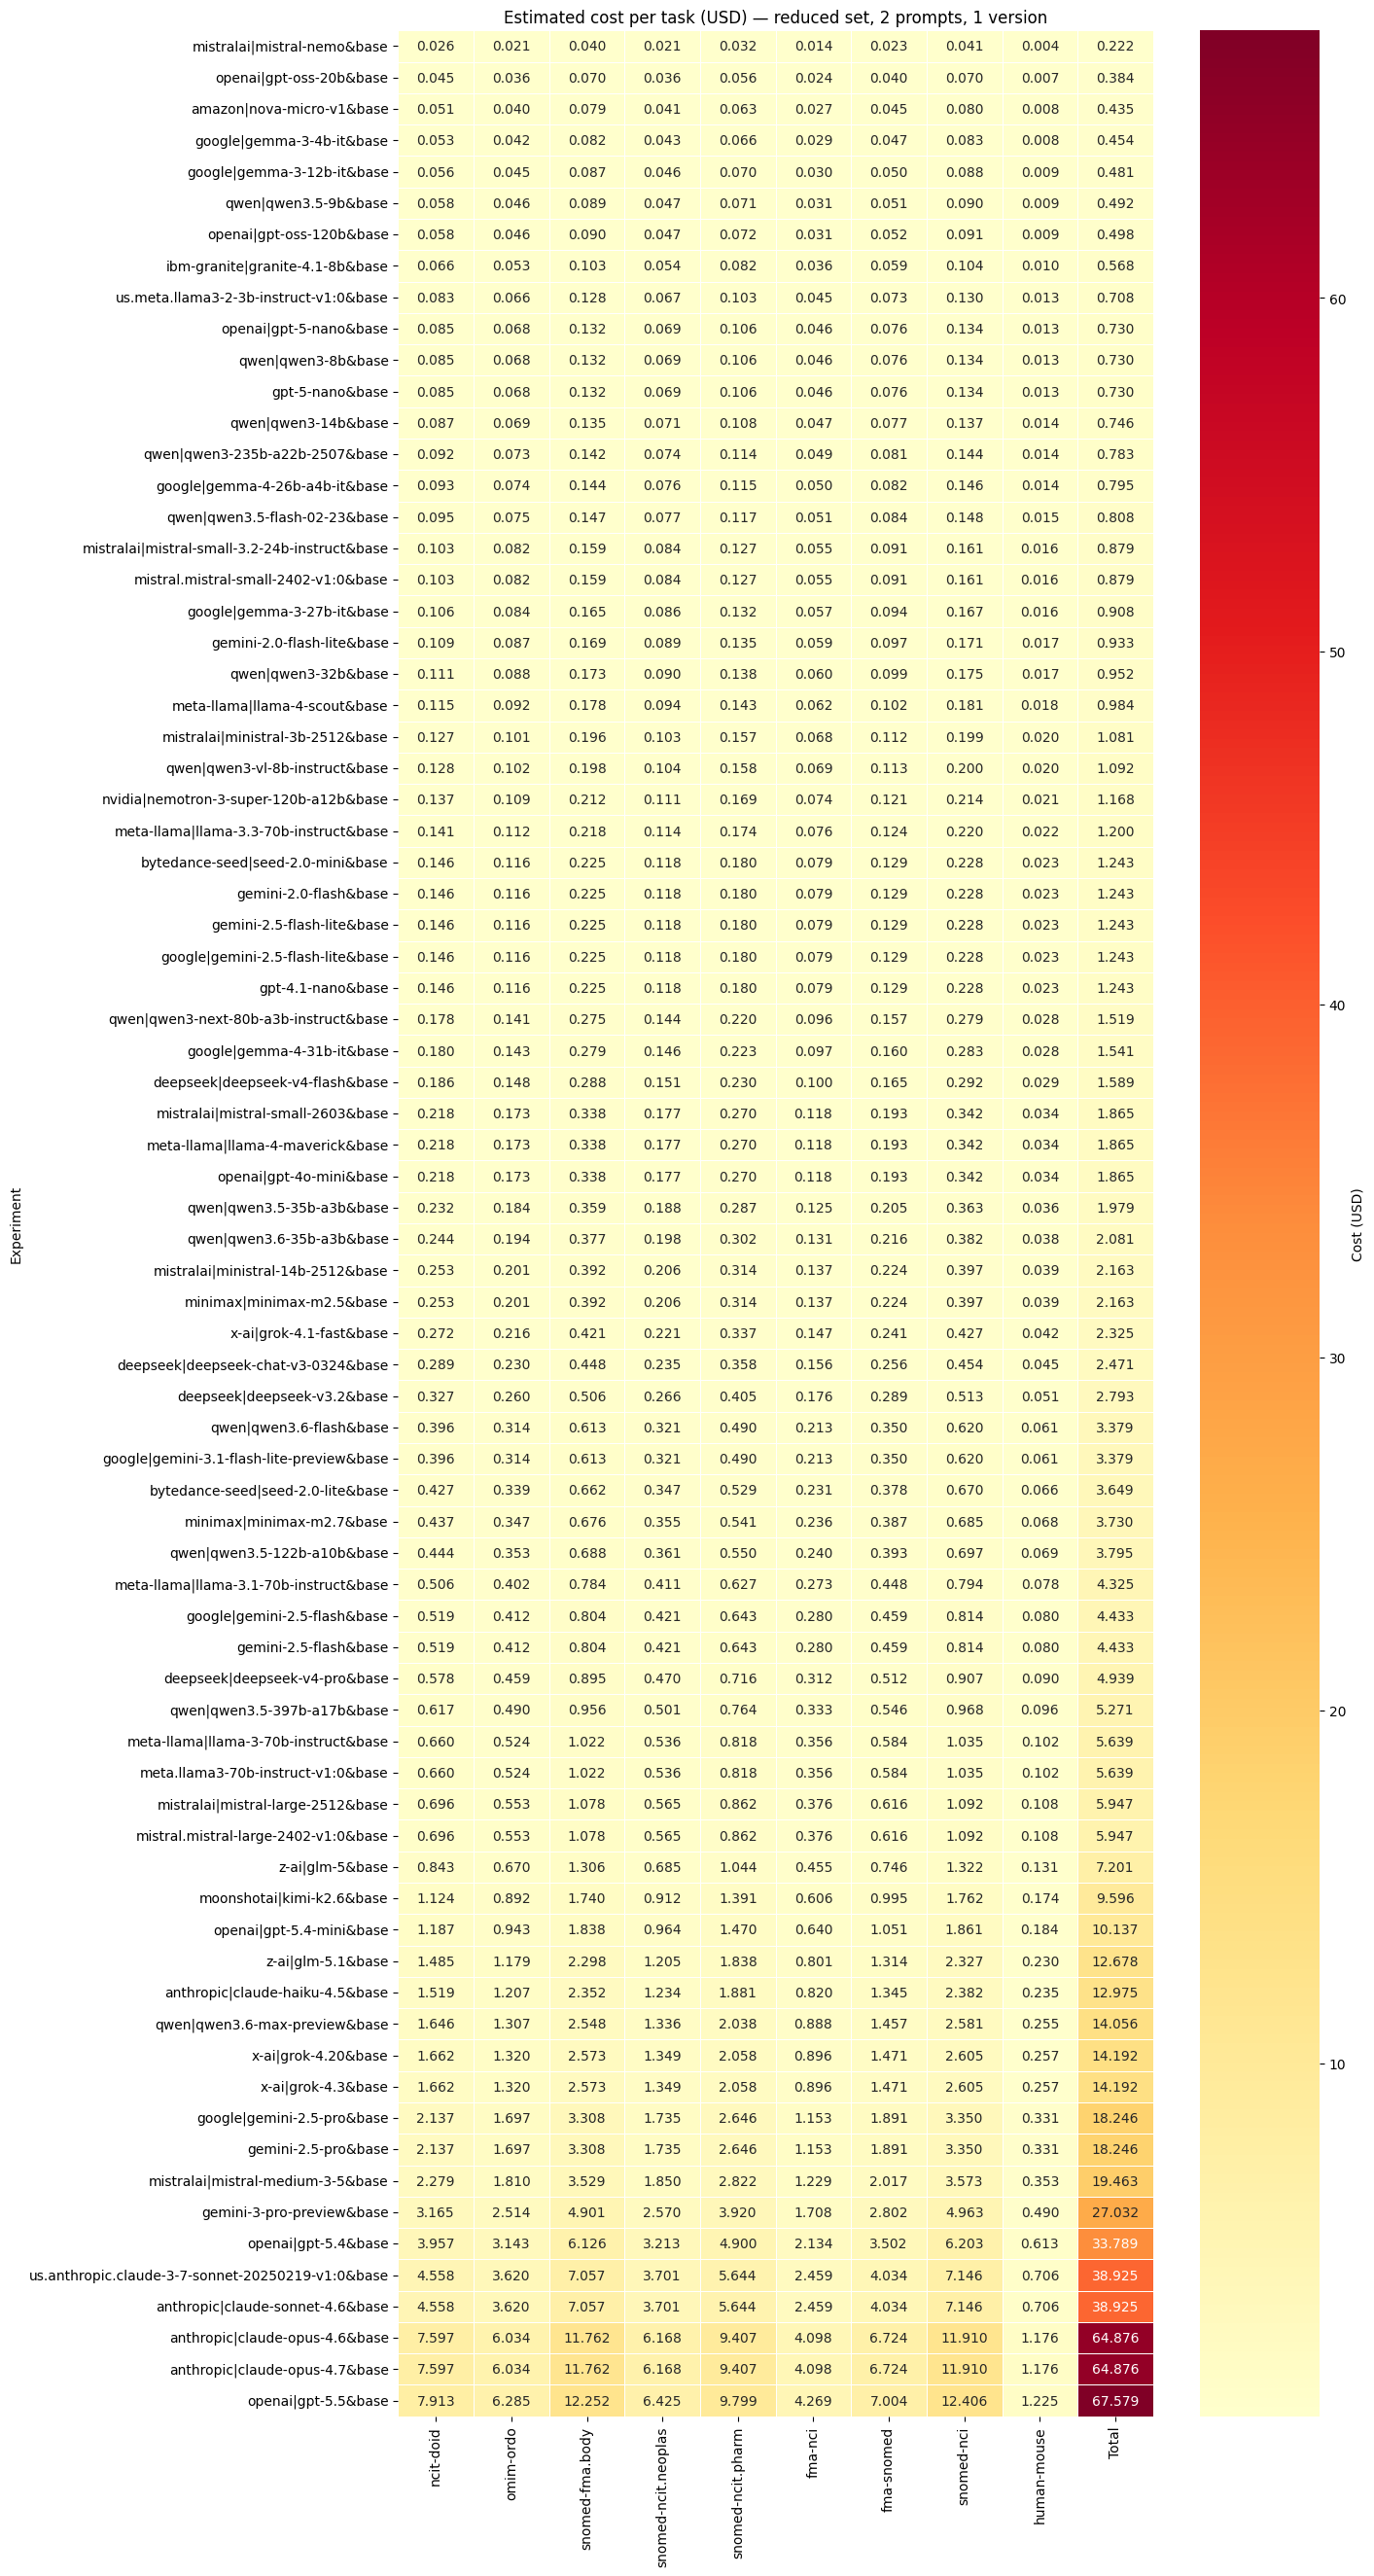


Saved cost estimates to metrics/estimations


In [15]:
wide_cost = build_cost_comparison_table(
    models=all_model_metadata,
    usage=base_usage,
    size="reduced",
    n_versions=1,
    n_prompts=2,
)

heatmap_data = wide_cost[wide_cost["Config"] == "base"].set_index("Experiment")
task_cols = [c for c in heatmap_data.columns if c in get_all_tasks()]
heatmap_data = heatmap_data[task_cols + ["Total"]].astype(float)
heatmap_data = heatmap_data.sort_values("Total", ascending=True)

fig, ax = plt.subplots(figsize=(14, max(8, len(heatmap_data) * 0.35)))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    ax=ax,
    linewidths=0.5,
    cbar_kws={"label": "Cost (USD)"},
)
ax.set_title("Estimated cost per task (USD) — reduced set, 2 prompts, 1 version")
plt.tight_layout()
plt.show()

save_path = METRICS_DIR / "estimations"
save_path.mkdir(parents=True, exist_ok=True)
wide_cost.to_csv(save_path / "cost_estimates_all_models.csv", index=False)
pricing_summary.to_csv(save_path / "model_pricing_summary.csv")
print(f"\nSaved cost estimates to {save_path}")